# Uniform heat storage: a gas boiler charging a mixed tank that serves a heat demand

This tutorial builds a gas boiler that feeds a uniform (fully mixed) hot-water tank, which serves a heat demand,
all connected with `FluidMixMapping`. The tank is at a single temperature; over each time step its temperature is
solved exactly, with its heat losses.

The demand rises above the boiler's maximum power in the evening: the tank, charged during the low-demand hours,
covers the rest.

See the [documentation of the model](https://pandaprosumer.readthedocs.io/en/latest/elements/uniform_heat_storage.html)
for the equations, the parameters and the edge cases.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pandaprosumer import (DFData, create_controlled_const_profile, create_controlled_gas_boiler,
                           create_controlled_heat_demand, create_controlled_uniform_heat_storage,
                           create_empty_prosumer_container, create_period)
from pandaprosumer.mapping import FluidMixMapping, GenericMapping
from pandaprosumer.run_time_series import run_timeseries

## Demand profile and period

One day, hourly. The demand is served at 60 °C and returns at 35 °C.

In [2]:
q_demand_kw = [20, 15, 15, 15, 20, 40, 70, 90, 60, 40, 30, 30,
               30, 30, 30, 40, 60, 100, 130, 130, 110, 80, 50, 30]
resol_s = 3600
start = "2020-01-01 00:00:00"
end = pd.Timestamp(start) + len(q_demand_kw) * pd.Timedelta(seconds=resol_s) - pd.Timedelta(seconds=1)

prosumer = create_empty_prosumer_container()
period = create_period(prosumer, resol_s, start, end, "utc", "default")
data = pd.DataFrame({"q_demand_kw": q_demand_kw},
                    index=pd.date_range(start, periods=len(q_demand_kw), freq=f"{resol_s}s", tz="utc"))
profile = create_controlled_const_profile(prosumer, input_columns=["q_demand_kw"], result_columns=["q_demand_kw"],
                                          data_source=DFData(data), period=period, level=0, order=0)

## Elements

- a gas boiler of 80 kW;
- a uniform tank of 5 m³ (5000 kg of water), usable from 60 °C (the demand's feed temperature) and charged at
  85 °C (`t_charge_target_c`), with a little heat loss to a 15 °C room; it starts at 62 °C. The size could be
  given as an energy capacity instead (`e_capacity_kwh` with `t_full_c`);
- the heat demand.

In [3]:
boiler = create_controlled_gas_boiler(prosumer, max_q_kw=80, heating_value_kj_per_kg=50e3, efficiency_percent=100,
                                      period=period, level=1, order=0, name="boiler")
tank = create_controlled_uniform_heat_storage(prosumer, mass_kg=5000, min_useful_temp_c=60, t_full_c=85,
                                              t_charge_target_c=85, u_w_per_m2k=0.5, area_wall_m2=17, t_ext_c=15,
                                              t_tank_init_c=62, period=period, level=1, order=1, name="tank")
demand = create_controlled_heat_demand(prosumer, t_feed_demand_c=60, t_return_demand_c=35,
                                       period=period, level=1, order=2, name="demand")

## Mappings

The demand profile drives the heat demand (`GenericMapping`); the water flows boiler → tank → demand
(`FluidMixMapping`).

In [4]:
GenericMapping(prosumer, initiator_id=profile, initiator_column="q_demand_kw", responder_id=demand,
               responder_column="q_demand_kw", order=0)
FluidMixMapping(prosumer, initiator_id=boiler, responder_id=tank, order=0)
FluidMixMapping(prosumer, initiator_id=tank, responder_id=demand, order=0)

run_timeseries(prosumer, period, False)

ts = prosumer.time_series
results = {name: ts[ts.name == name].data_source.iloc[0].df for name in ("boiler", "tank", "demand")}
tank_df, boiler_df, demand_df = results["tank"], results["boiler"], results["demand"]
tank_df[["q_received_kw", "q_charge_kw", "q_discharge_kw", "q_delivered_kw", "q_loss_kw", "t_tank_c",
         "e_stored_kwh"]].round(2)

,q_received_kw,q_charge_kw,q_discharge_kw,q_delivered_kw,q_loss_kw,t_tank_c,e_stored_kwh
2020-01-01 00:00:00+00:00,80.00,59.96,0.00,20.02,0.45,72.22,59.47
2020-01-01 01:00:00+00:00,62.35,47.31,0.00,15.01,0.53,80.24,106.32
2020-01-01 02:00:00+00:00,32.82,17.76,0.00,15.01,0.57,83.19,123.58
2020-01-01 03:00:00+00:00,21.97,6.90,0.00,15.01,0.58,84.27,129.92
2020-01-01 04:00:00+00:00,21.52,1.44,0.00,20.02,0.59,84.42,130.78
2020-01-01 05:00:00+00:00,40.64,0.53,0.00,40.04,0.59,84.41,130.73
2020-01-01 06:00:00+00:00,70.75,0.59,0.00,70.07,0.59,84.41,130.73
2020-01-01 07:00:00+00:00,80.00,0.00,10.09,90.09,0.58,82.57,119.98
2020-01-01 08:00:00+00:00,69.39,9.17,0.00,60.06,0.58,84.04,128.60
2020-01-01 09:00:00+00:00,42.97,2.82,0.00,40.04,0.59,84.43,130.84


## Results

The boiler runs at its maximum when the demand exceeds it; the tank charges during the low-demand hours
(towards 85 °C) and discharges in the evening peak until it reaches its minimum useful temperature.

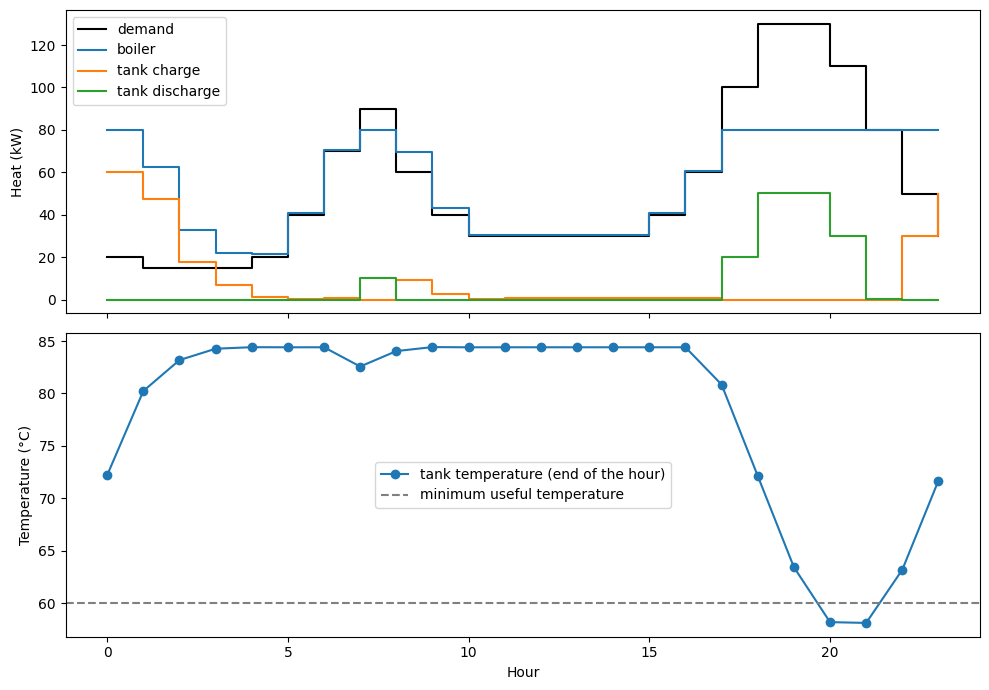

In [5]:
fig, (ax_q, ax_t) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
hours = np.arange(len(q_demand_kw))
ax_q.step(hours, q_demand_kw, where="post", label="demand", color="black")
ax_q.step(hours, boiler_df["q_kw"], where="post", label="boiler")
ax_q.step(hours, tank_df["q_charge_kw"], where="post", label="tank charge")
ax_q.step(hours, tank_df["q_discharge_kw"], where="post", label="tank discharge")
ax_q.set_ylabel("Heat (kW)")
ax_q.legend()
ax_t.plot(hours, tank_df["t_tank_c"], marker="o", label="tank temperature (end of the hour)")
ax_t.axhline(60, color="grey", linestyle="--", label="minimum useful temperature")
ax_t.set_ylabel("Temperature (°C)")
ax_t.set_xlabel("Hour")
ax_t.legend()
plt.tight_layout()

## Checks

The heat the demand received is the heat the tank delivered, the heat the tank received is the heat the boiler
produced, and the tank's balance closes: charge − discharge − losses = change of the stored energy.

In [6]:
print("demand uncovered (kWh):", demand_df["q_uncovered_kw"].clip(lower=0).sum().round(2))
print("boiler -> tank gap (kW):", (boiler_df["q_kw"] - tank_df["q_received_kw"]).abs().max().round(3))
print("tank -> demand gap (kW):", (tank_df["q_delivered_kw"] - demand_df["q_received_kw"]).abs().max().round(3))
balance_kwh = (tank_df["q_charge_kw"] - tank_df["q_discharge_kw"] - tank_df["q_loss_kw"]).cumsum() * resol_s / 3600
print("tank balance gap (kWh):", (balance_kwh - tank_df["e_stored_kwh"]).abs().max().round(3))

demand uncovered (kWh): 0.0
boiler -> tank gap (kW): 0.008
tank -> demand gap (kW): 0.02
tank balance gap (kWh): 0.563
